In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
file_path = r"\geographic-information-system-analyzer\data\raw\harbiye_mahalle_all_poi_20251013_160536.json"

In [3]:
with open(file_path, "r", encoding="utf-8") as f:
    poi_data = json.load(f)

In [8]:
df = pd.json_normalize(poi_data["data"])
print("İlk 5 satır:")
display(df.tail(100))

İlk 5 satır:


,id,name,lat,lon,tag,tags.crossing,tags.highway,tags.traffic_signals,tags.name,tags.name:ar,...,tags.diet:halal,tags.diet:local,tags.diet:meat,tags.diet:organic,tags.layer,tags.parking,tags.animal_shelter,tags.couplings,tags.fire_hydrant:type,tags.noexit
7171,12854459759,None,41.041428,28.990420,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7172,12854459760,None,41.041072,28.990397,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7173,12854459761,None,41.040763,28.989622,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7174,12854459762,None,41.041340,28.990401,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7175,12854459763,None,41.041255,28.990110,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7266,13106689059,Arjantin Başkonsolosluğu,41.040020,28.992060,addr:city,NaN,NaN,NaN,Arjantin Başkonsolosluğu,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7267,13110202580,None,39.883760,32.839399,None,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7268,13110202581,None,39.883784,32.838652,None,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7269,13165639042,Kadırgalar Caddesi,41.042626,28.992858,bus,NaN,bus_stop,NaN,Kadırgalar Caddesi,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
print("\nDataFrame info:")
print(df.info())


DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7271 entries, 0 to 7270
Columns: 230 entries, id to tags.noexit
dtypes: float64(2), int64(1), object(227)
memory usage: 12.8+ MB
None


In [16]:
print("\nPOI sayısı:", len(df))
print("Tag dağılımı:")
tag_counts = df['tag'].value_counts()
print(tag_counts)


POI sayısı: 7271
Tag dağılımı:
tag
amenity              71
denotation           58
leisure              38
natural              34
addr:city            31
name                 18
addr:housenumber     18
brand                17
crossing             15
highway              15
access               13
barrier              11
name:en               6
door                  6
aerialway             5
bus                   5
bench                 4
addr:postcode         4
addr:street           3
addr:district         3
artwork_type          2
railway               2
tourism               2
office                2
alt_name              2
name:de               1
emergency             1
healthcare            1
direction             1
covered               1
crossing:markings     1
building              1
craft                 1
couplings             1
noexit                1
Name: count, dtype: int64


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34]),
 [Text(0, 0, 'amenity'),
  Text(1, 0, 'denotation'),
  Text(2, 0, 'leisure'),
  Text(3, 0, 'natural'),
  Text(4, 0, 'addr:city'),
  Text(5, 0, 'name'),
  Text(6, 0, 'addr:housenumber'),
  Text(7, 0, 'brand'),
  Text(8, 0, 'crossing'),
  Text(9, 0, 'highway'),
  Text(10, 0, 'access'),
  Text(11, 0, 'barrier'),
  Text(12, 0, 'name:en'),
  Text(13, 0, 'door'),
  Text(14, 0, 'aerialway'),
  Text(15, 0, 'bus'),
  Text(16, 0, 'bench'),
  Text(17, 0, 'addr:postcode'),
  Text(18, 0, 'addr:street'),
  Text(19, 0, 'addr:district'),
  Text(20, 0, 'artwork_type'),
  Text(21, 0, 'railway'),
  Text(22, 0, 'tourism'),
  Text(23, 0, 'office'),
  Text(24, 0, 'alt_name'),
  Text(25, 0, 'name:de'),
  Text(26, 0, 'emergency'),
  Text(27, 0, 'healthcare'),
  Text(28, 0, 'direction'),
  Text(29, 0, 'covered'),
  Text(30, 0, 'crossing:markings')

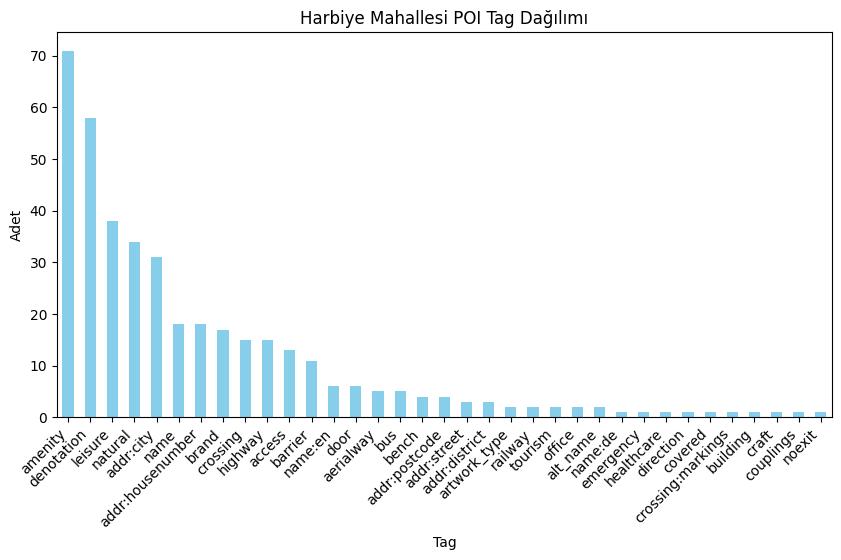

In [17]:
# --- Tag dağılımı görselleştirme (Bar chart) ---
plt.figure(figsize=(10,5))
tag_counts.plot(kind='bar', color='skyblue')
plt.title("Harbiye Mahallesi POI Tag Dağılımı")
plt.xlabel("Tag")
plt.ylabel("Adet")
plt.xticks(rotation=45, ha='right')

In [18]:
num_with_name = df['name'].notnull().sum()
num_without_name = df['name'].isnull().sum()
print(f"\nİsimli POI sayısı: {num_with_name}")
print(f"İsimsiz POI sayısı: {num_without_name}")

# --- En sık görülen POI tag'leri ---
print("\nEn sık görülen 10 POI tag'i:")
print(tag_counts.head(10))


İsimli POI sayısı: 129
İsimsiz POI sayısı: 7142

En sık görülen 10 POI tag'i:
tag
amenity             71
denotation          58
leisure             38
natural             34
addr:city           31
name                18
addr:housenumber    18
brand               17
crossing            15
highway             15
Name: count, dtype: int64


Sadece isimli POI sayısı: 129


,id,name,lat,lon,tag,tags.crossing,tags.highway,tags.traffic_signals,tags.name,tags.name:ar,...,tags.diet:halal,tags.diet:local,tags.diet:meat,tags.diet:organic,tags.layer,tags.parking,tags.animal_shelter,tags.couplings,tags.fire_hydrant:type,tags.noexit
139,278615640,Divan Hotel,41.041102,28.987041,name,NaN,NaN,NaN,Divan Hotel,فندق ديفان,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,278615643,Garanti Bankası,41.042706,28.986852,addr:postcode,NaN,NaN,NaN,Garanti Bankası,غرانتي بنك,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,1346157990,Askerî Müze,41.048876,28.988243,addr:postcode,NaN,NaN,NaN,Askerî Müze,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
250,1665857196,Süslü Cafe,41.043980,28.994794,amenity,NaN,NaN,NaN,Süslü Cafe,مقهى سوسلو,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
253,1773243353,Maçka,41.044358,28.995020,bench,NaN,bus_stop,NaN,Maçka,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: title={'center': 'İsimli POI Tag Dağılımı'}, xlabel='tag'>

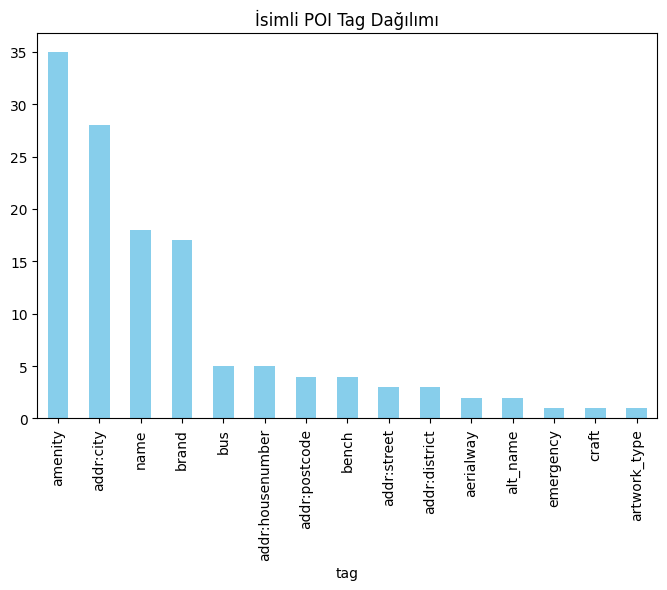

In [19]:
# Sadece isimli POI'leri al
named_df = df[df['name'].notna()].copy()

print("Sadece isimli POI sayısı:", len(named_df))
display(named_df.head())

# Tag dağılımı (sadece isimli POI)
tag_counts_named = named_df['tag'].value_counts()
tag_counts_named.plot(kind='bar', figsize=(8,5), color='skyblue', title="İsimli POI Tag Dağılımı")


In [20]:
named_df.shape

(129, 230)

In [21]:
named_df.head()

,id,name,lat,lon,tag,tags.crossing,tags.highway,tags.traffic_signals,tags.name,tags.name:ar,...,tags.diet:halal,tags.diet:local,tags.diet:meat,tags.diet:organic,tags.layer,tags.parking,tags.animal_shelter,tags.couplings,tags.fire_hydrant:type,tags.noexit
139,278615640,Divan Hotel,41.041102,28.987041,name,NaN,NaN,NaN,Divan Hotel,فندق ديفان,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
140,278615643,Garanti Bankası,41.042706,28.986852,addr:postcode,NaN,NaN,NaN,Garanti Bankası,غرانتي بنك,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,1346157990,Askerî Müze,41.048876,28.988243,addr:postcode,NaN,NaN,NaN,Askerî Müze,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
250,1665857196,Süslü Cafe,41.043980,28.994794,amenity,NaN,NaN,NaN,Süslü Cafe,مقهى سوسلو,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
253,1773243353,Maçka,41.044358,28.995020,bench,NaN,bus_stop,NaN,Maçka,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,id,name,lat,lon,tag,tags.crossing,tags.highway,tags.traffic_signals,tags.name,tags.name:ar,...,tags.diet:meat,tags.diet:organic,tags.layer,tags.parking,tags.animal_shelter,tags.couplings,tags.fire_hydrant:type,tags.noexit,ilce,mahalle
139,278615640,Divan Hotel,41.041102,28.987041,name,NaN,NaN,NaN,Divan Hotel,فندق ديفان,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
140,278615643,Garanti Bankası,41.042706,28.986852,addr:postcode,NaN,NaN,NaN,Garanti Bankası,غرانتي بنك,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
211,1346157990,Askerî Müze,41.048876,28.988243,addr:postcode,NaN,NaN,NaN,Askerî Müze,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
250,1665857196,Süslü Cafe,41.043980,28.994794,amenity,NaN,NaN,NaN,Süslü Cafe,مقهى سوسلو,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
253,1773243353,Maçka,41.044358,28.995020,bench,NaN,bus_stop,NaN,Maçka,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye


tag,addr:city,addr:district,addr:housenumber,addr:postcode,addr:street,aerialway,alt_name,amenity,artwork_type,bench,brand,bus,craft,emergency,name
mahalle,,,,,,,,,,,,,,,
Harbiye,28,3,5,4,3,2,2,35,1,4,17,5,1,1,18


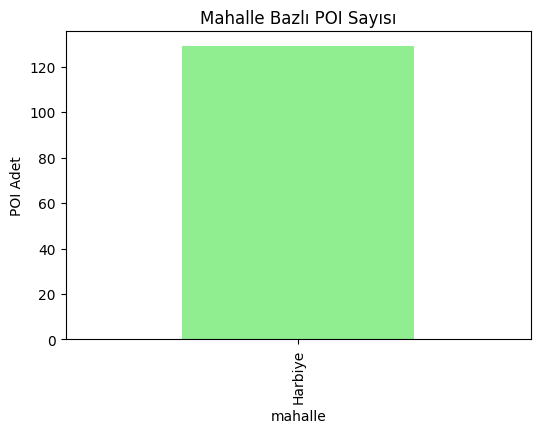

In [22]:
import pandas as pd

# Örnek: Harbiye DataFrame
named_df = named_df.copy()  # mevcut DataFrame'den kopya

# İlçe ve mahalle sütunları ekle
named_df['ilce'] = 'Şişli'
named_df['mahalle'] = 'Harbiye'

# Kontrol
display(named_df.head())

# Tag dağılımı mahalle bazlı
tag_counts_by_mahalle = named_df.groupby(['mahalle', 'tag']).size().unstack(fill_value=0)
display(tag_counts_by_mahalle)

# Örnek görselleştirme: mahalle bazlı POI sayısı
import matplotlib.pyplot as plt

tag_counts_by_mahalle.sum(axis=1).plot(kind='bar', color='lightgreen', figsize=(6,4))
plt.title("Mahalle Bazlı POI Sayısı")
plt.ylabel("POI Adet")
plt.show()


In [23]:
named_df.head()

,id,name,lat,lon,tag,tags.crossing,tags.highway,tags.traffic_signals,tags.name,tags.name:ar,...,tags.diet:meat,tags.diet:organic,tags.layer,tags.parking,tags.animal_shelter,tags.couplings,tags.fire_hydrant:type,tags.noexit,ilce,mahalle
139,278615640,Divan Hotel,41.041102,28.987041,name,NaN,NaN,NaN,Divan Hotel,فندق ديفان,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
140,278615643,Garanti Bankası,41.042706,28.986852,addr:postcode,NaN,NaN,NaN,Garanti Bankası,غرانتي بنك,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
211,1346157990,Askerî Müze,41.048876,28.988243,addr:postcode,NaN,NaN,NaN,Askerî Müze,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
250,1665857196,Süslü Cafe,41.043980,28.994794,amenity,NaN,NaN,NaN,Süslü Cafe,مقهى سوسلو,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye
253,1773243353,Maçka,41.044358,28.995020,bench,NaN,bus_stop,NaN,Maçka,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Şişli,Harbiye


In [25]:
named_df.shape

(129, 232)

In [24]:
named_df.columns

Index(['id', 'name', 'lat', 'lon', 'tag', 'tags.crossing', 'tags.highway',
       'tags.traffic_signals', 'tags.name', 'tags.name:ar',
       ...
       'tags.diet:meat', 'tags.diet:organic', 'tags.layer', 'tags.parking',
       'tags.animal_shelter', 'tags.couplings', 'tags.fire_hydrant:type',
       'tags.noexit', 'ilce', 'mahalle'],
      dtype='object', length=232)

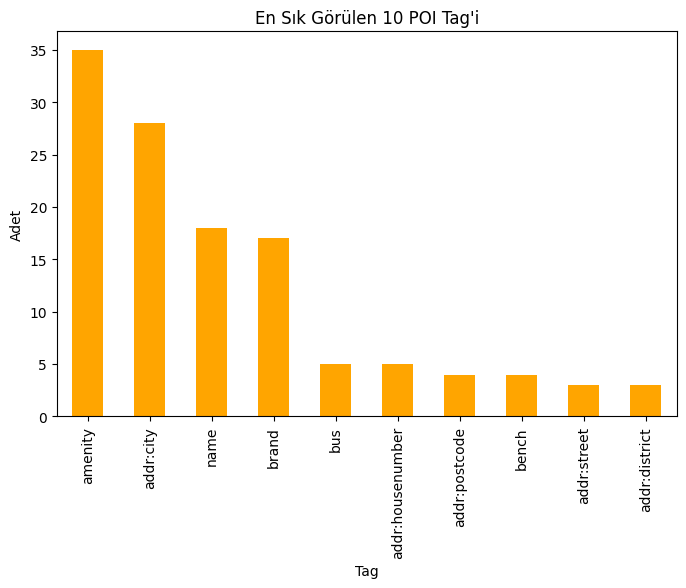

In [27]:
# Tag bazlı toplam POI sayısı
tag_counts = named_df['tag'].value_counts().head(10)  # en sık görülen 10 tag

plt.figure(figsize=(8,5))
tag_counts.plot(kind='bar', color='orange')
plt.title("En Sık Görülen 10 POI Tag'i")
plt.ylabel("Adet")
plt.xlabel("Tag")
plt.show()


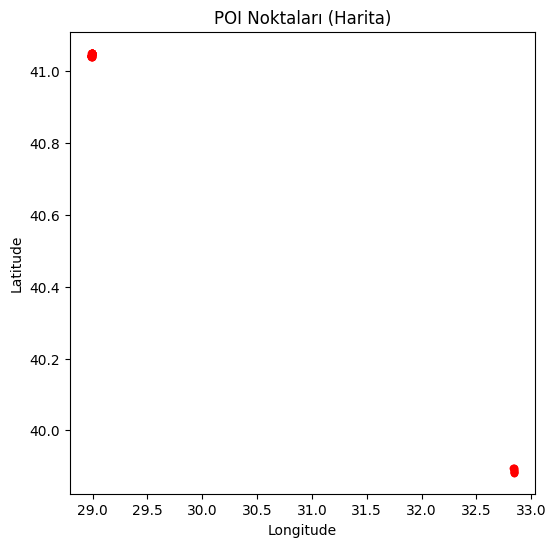

In [29]:
plt.figure(figsize=(6,6))
plt.scatter(named_df['lon'], named_df['lat'], c='red', alpha=0.6, s=20)
plt.title("POI Noktaları (Harita)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [30]:
import pandas as pd
from pathlib import Path
from datetime import datetime

# Kaydedilecek klasör
folder = r"/geographic-information-system-analyzer/data/raw"
Path(folder).mkdir(parents=True, exist_ok=True)

# Excel dosya ismi (timestamp ile)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
file_path = Path(folder) / f"harbiye_named_poi_{timestamp}.xlsx"

# Excel olarak kaydet
named_df.to_excel(file_path, index=False)

print(f"named_df Excel olarak kaydedildi: {file_path}")


named_df Excel olarak kaydedildi: C:\Users\lunaf\Desktop\Projects\geographic-information-system-analyzer\data\raw\harbiye_named_poi_20251013_161532.xlsx
